# YOLOV8 Object Detections

In this tutorial, we will learn the following:


*   How to run inference with YOLOV8 on a single image
*   How to display the results on the image


# Pre-requisites
First, we will need to install `ultralytics`.

In [1]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 4.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 4.3 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 4.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 3.6 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 4.0 MB/s  0:00:12m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 3.9 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 911.5/911.5 kB 4.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 3.8 MB/s  0:00:12m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.6/80.6 MB 4.2 MB/s  0:00:19m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 4.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 3.6 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6

# Running a YOLOV8 model on a sample image

We have to get the image from elsewhere, but the model itself is already present on the Google server

In [2]:
# wget is a way of getting a file
!wget https://ultralytics.com/images/bus.jpg

zsh:1: command not found: wget


In [104]:
from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")  # loading a pretrained model, in this case the YOLOV8 nano model
# img = cv2.imread("bus.jpg")
img = cv2.imread("./bus.jpeg")

Display the image to make sure you know what you are working with

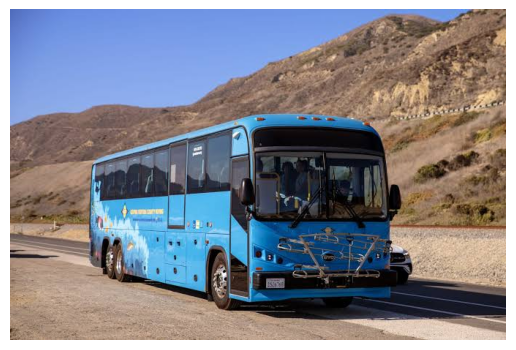

In [105]:
# from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt

def temp_imshow(img, title=None):
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img)
    else:
        plt.imshow(img, cmap="gray")
    if title:
        plt.title(title)
    plt.axis("off")
    plt.show()
temp_imshow(img)


Use the model to get detection results from the image, and display them

In [276]:
results = model(img)
print(results)


0: 448x640 4 persons, 28 cars, 4 buss, 266.1ms
Speed: 19.5ms preprocess, 266.1ms inference, 22.5ms postprocess per image at shape (1, 3, 448, 640)
[ultralytics.engine.results.Results object with attributes:

boxes: ultralytics.engine.results.Boxes object
colors: None
depth: None
keypoints: None
masks: ultralytics.engine.results.Masks object
names: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 4

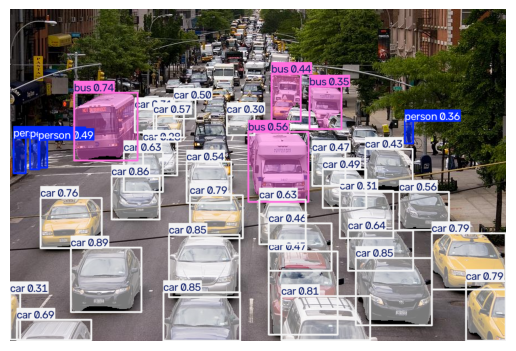

In [277]:
# why don't we pass the image to plot? it becomes a yolo result object?
# doesn't allow us to store the images

img2 = results[0].plot()
temp_imshow(img2)

In [108]:
# print(results)
print(len(results[0].boxes))
print(results[0].boxes)

2
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([5., 2.])
conf: tensor([0.9438, 0.2769])
data: tensor([[1.0100e+02, 1.4342e+02, 5.4025e+02, 4.1171e+02, 9.4381e-01, 5.0000e+00],
        [5.1944e+02, 3.1965e+02, 5.5032e+02, 3.7740e+02, 2.7695e-01, 2.0000e+00]])
id: None
is_track: False
orig_shape: (452, 678)
shape: torch.Size([2, 6])
xywh: tensor([[320.6237, 277.5639, 439.2510, 268.2940],
        [534.8819, 348.5203,  30.8810,  57.7500]])
xywhn: tensor([[0.4729, 0.6141, 0.6479, 0.5936],
        [0.7889, 0.7711, 0.0455, 0.1278]])
xyxy: tensor([[100.9982, 143.4169, 540.2492, 411.7109],
        [519.4414, 319.6453, 550.3224, 377.3953]])
xyxyn: tensor([[0.1490, 0.3173, 0.7968, 0.9109],
        [0.7661, 0.7072, 0.8117, 0.8349]])


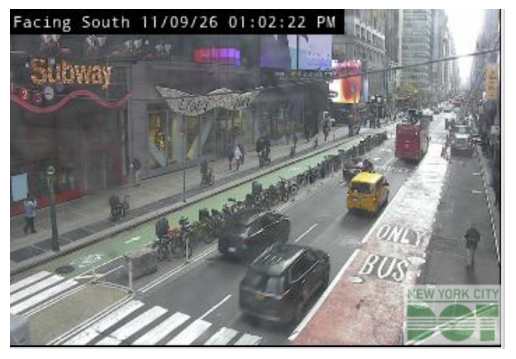

In [99]:
# draw bounding boxes for each detection on the image

for result in results:
  for box in result.boxes:
    # what are the cv2 shapes and drawing methods?
    None
    # cv2.rectangle(img, (int(box.xyxy[0][0]), int(box.xyxy[0][1])), (int(box.xyxy[0][2]), int(box.xyxy[0][3])), (0,0,0), 3, cv2.LINE_AA)

temp_imshow(img)

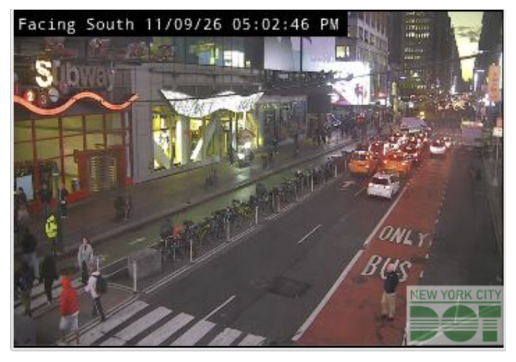

(101, 143, 439, 269)
(101, 143, 439, 269) foreground pixels: 27869
(519, 320, 31, 57)
(519, 320, 31, 57) foreground pixels: 0


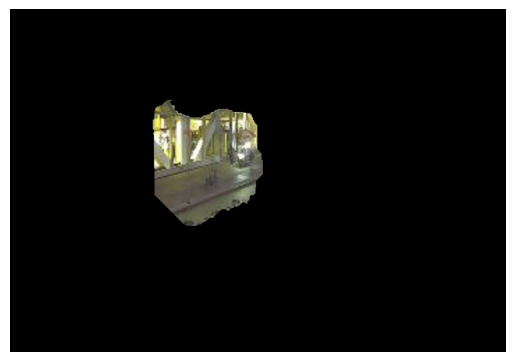

In [113]:
# !pip install numpy  

# CV2 GRABCUT CODE. ONE PASS FOR EACH BOX? WORKS POORLY ON IMAGES WITH MANY OBJECTS
import numpy as np

img3 = cv2.imread('./TS_2.png')
assert img3 is not None, "file could not be read, check with os.path.exists()"
temp_imshow(img3)

H, W = img3.shape[:2]
combined = np.zeros((H, W), np.uint8) 
# print('res len',len(results))
for result in results:
  for i, box in enumerate(result.boxes):
    assert img3 is not None, "file could not be read, check with os.path.exists()"
    mask = np.zeros((H, W), np.uint8)
    
    bgdModel = np.zeros((1,65),np.float64)
    fgdModel = np.zeros((1,65),np.float64)
   
    x1, y1, x2, y2 = [round(v) for v in box.xyxy[0].tolist()]
    rect = (x1, y1, x2 - x1, y2 - y1)
    print(rect)
    cv2.grabCut(img3,mask,rect,bgdModel,fgdModel,10,cv2.GC_INIT_WITH_RECT)

    fg = np.where((mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD), 1, 0).astype(np.uint8)
    print(rect, "foreground pixels:", fg.sum())     # 0 means GrabCut found nothing
    combined |= fg

cutout = img3 * combined[:, :, np.newaxis]               # original img stays intact
temp_imshow(cutout)






58 objects found


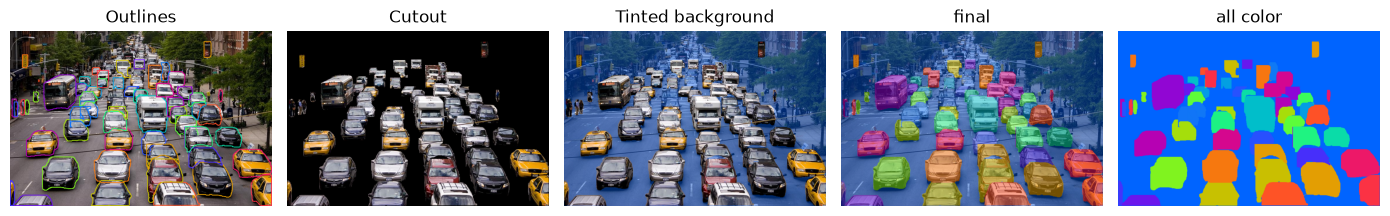

In [275]:
import math
# 1. Load the segmentation model (downloads on first use)
model = YOLO("yolov8n-seg.pt")

# isolate background and tint, SAM model? sam might be able to isolate roads, buildings
# tint each object a different color
# k means color palate reduction?

# 2. Load the image
img = cv2.imread("./traffic_2.jpg")
# img = cv2.imread("./TS_2.png")
assert img is not None, "file could not be read, check the path"
H, W = img.shape[:2]

# 3. Run inference (one image, so take the first result)
result = model(img, conf=0.1, verbose=False)[0]

if result.masks is None:
    print("No objects detected")
else:
    print(len(result.masks.xy), "objects found")

    # 4. Draw outlines
    frequency = .3
    outlined = img.copy()
    for i, poly in enumerate(result.masks.xy):                      # each poly is (N, 2) pixel coords
        red   = math.sin(frequency*i + 0) * 127 + 128;
        green = math.sin(frequency*i + 2) * 127 + 128;
        blue  = math.sin(frequency*i + 4) * 127 + 128;
        cv2.polylines(outlined, [poly.astype(np.int32)], True, (blue, green, red), 2)

    # TINT BG, COLOR POLYS, COMBINE

    # MASKS
    # poly1_bg0_mask is single channel mask, matching the image's height and width, with all ZEROS
    obj1_bg0_mask = np.zeros((H,W), np.uint8)
    # color layer is initialized with all zeros, but is a 3 channel image, so that it can retain the color from the original image 
    # it will later be filled with its own color
    object_color_layer_mask = np.zeros_like(img)   

    for j, poly in enumerate(result.masks.xy):
        red   = math.sin(frequency * j + 0) * 127 + 128
        green = math.sin(frequency * j + 2) * 127 + 128
        blue  = math.sin(frequency * j + 4) * 127 + 128
        # YOLO result produces float coordinates, cv2 takes int
        pts = poly.astype(np.int32)

        # in polygons, assign pixes to 1 on combined mask
        cv2.fillPoly(obj1_bg0_mask, [pts], 1)
        # in polgyons, assign pixels to on color mask for each polygon
        cv2.fillPoly(object_color_layer_mask, [pts], (int(blue), int(green), int(red)))   # BGR ints
    
    # TINT BG
    # solid color image matching size of original image
    solid_color_layer = np.full_like(img, (255, 100, 0))                 # BGR blue
    # cv2.addWeighted(src1, alpha, src2, beta, gamma)
    # combine the original image with the solid color layer at alpha .6
    tinted_image = cv2.addWeighted(img, 0.6, solid_color_layer, 0.4, 0)

    # REPLACE BG WITH TINTED BG
    plain_img = img.copy()
    # background mask, for each pix in poly1_bg0_mask, create boolean array where 0 pix == True (is bg), and 1 pix = False (detected obj)
    # BG is TRUE, DETECTED OBJ POLYGON is FALSE
    mask_boolean_array = np.where(obj1_bg0_mask == 1, True, False)

    # ~ is NumPy’s element-wise NOT. On a boolean array it flips every True to False and every False to True.
    # so here we replace the background (0 and then False), with the background of the tinted image. 
    plain_img[~mask_boolean_array] = tinted_image[~mask_boolean_array]
    # rename as tinted
    tinted_bg = plain_img

    # solid color plus colored cutouts?
    # wherever the mask boolean array is true (obj), replace with values from the colored object layer
    # this places the colored detected obj layer on top of the solid blue image
    solid_color_layer[mask_boolean_array] = object_color_layer_mask[mask_boolean_array]
  
    

    # multiply image by mask, so that img px is multiplied by 1 for poly px, and 0 for bg px
    cutout = img * obj1_bg0_mask[:, :, np.newaxis]

    # Tinted objects: blend each object's color into the original pixels
    original_image_with_tinted_object_overlay = cv2.addWeighted(img, 0.5, object_color_layer_mask, 0.5, 0)

    # here we start with the blue tinted image
    # then we isolate the detected objects with the 1, True, mask, and replace them with the tinted objects. 
    final = tinted_image.copy()
    final[mask_boolean_array] = original_image_with_tinted_object_overlay[mask_boolean_array]

    # GIVE MICHAEL SHORT DESCRIPTION OF FINAL PROJECT BY WEEKEND?
    # next step, hook up to webcam

    # 6. Show both (convert BGR to RGB for matplotlib)
    fig, axes = plt.subplots(1, 5, figsize=(14, 6))
    axes[0].imshow(cv2.cvtColor(outlined, cv2.COLOR_BGR2RGB)); axes[0].set_title("Outlines")
    axes[1].imshow(cv2.cvtColor(cutout, cv2.COLOR_BGR2RGB));   axes[1].set_title("Cutout")
    axes[2].imshow(cv2.cvtColor(tinted_bg, cv2.COLOR_BGR2RGB)); axes[2].set_title("Tinted background")
    axes[3].imshow(cv2.cvtColor(final, cv2.COLOR_BGR2RGB)); axes[3].set_title("final")
    axes[4].imshow(cv2.cvtColor(solid_color_layer, cv2.COLOR_BGR2RGB)); axes[4].set_title("all color")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()